In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from xgboost import XGBRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.inspection import permutation_importance

In [2]:
waves = pd.read_csv(r"C:\Users\justi\OneDrive\Documents\2026-2\GEOL_415\Assignments\Data\Waves_2023.txt",
    sep=r"\s+"
)

In [3]:
waves = waves[
    (waves["WVHT"] < 99) &
    (waves["DPD"] < 99) &
    (waves["APD"] < 99) &
    (waves["MWD"] < 999) &
    (waves["WTMP"] < 999)
].copy()

print("Usable observations:", len(waves))

Usable observations: 17276


In [4]:
direction_radians = np.deg2rad(waves["MWD"])

X = pd.DataFrame({
    "DPD": waves["DPD"],
    "APD": waves["APD"],
    "MWD_sin": np.sin(direction_radians),
    "MWD_cos": np.cos(direction_radians),
    "WTMP": waves["WTMP"]
})

y = waves["WVHT"]

In [5]:
X_train_val, X_test, y_train_val, y_test = train_test_split(
    X,
    y,
    test_size=0.15,
    random_state=42
)

X_train, X_val, y_train, y_val = train_test_split(
    X_train_val,
    y_train_val,
    test_size=0.15 / 0.85,
    random_state=42
)

print("Training observations:", len(X_train))
print("Validation observations:", len(X_val))
print("Test observations:", len(X_test))

Training observations: 12092
Validation observations: 2592
Test observations: 2592


In [6]:
linear_model = LinearRegression()
linear_model.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](5,)","[-0.01, 0.11, 0.27, 0.55,-0.04]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](5,)","['DPD','APD','MWD_sin','MWD_cos','WTMP']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,1.457
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,5
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(5)


In [7]:
xgb_model = XGBRegressor(
    n_estimators=25,       # exactly 25 boosting iterations
    learning_rate=0.1,
    max_depth=3,
    objective="reg:squarederror",
    random_state=42,
    n_jobs=-1
)

xgb_model.fit(X_train, y_train)

,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,None
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",None
,feature_types feature_types: typing.Optional[typing.Sequence[str]].. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


In [8]:
def evaluate_model(model, model_name, datasets):
    results = []

    for dataset_name, X_data, y_data in datasets:
        predictions = model.predict(X_data)

        results.append({
            "Model": model_name,
            "Dataset": dataset_name,
            "RMSE": np.sqrt(mean_squared_error(y_data, predictions)),
            "MAE": mean_absolute_error(y_data, predictions),
            "R2": r2_score(y_data, predictions)
        })

    return results


datasets = [
    ("Training", X_train, y_train),
    ("Validation", X_val, y_val),
    ("Test", X_test, y_test)
]

results = []

results.extend(
    evaluate_model(
        linear_model,
        "Linear regression",
        datasets
    )
)

results.extend(
    evaluate_model(
        xgb_model,
        "XGBoost (25 trees)",
        datasets
    )
)

results = pd.DataFrame(results)

print(
    results.round(4).to_string(index=False)
)



             Model    Dataset   RMSE    MAE     R2
 Linear regression   Training 0.4367 0.2973 0.3231
 Linear regression Validation 0.4245 0.2909 0.3119
 Linear regression       Test 0.4289 0.2900 0.3244
XGBoost (25 trees)   Training 0.3633 0.2417 0.5315
XGBoost (25 trees) Validation 0.3536 0.2350 0.5226
XGBoost (25 trees)       Test 0.3691 0.2422 0.4995


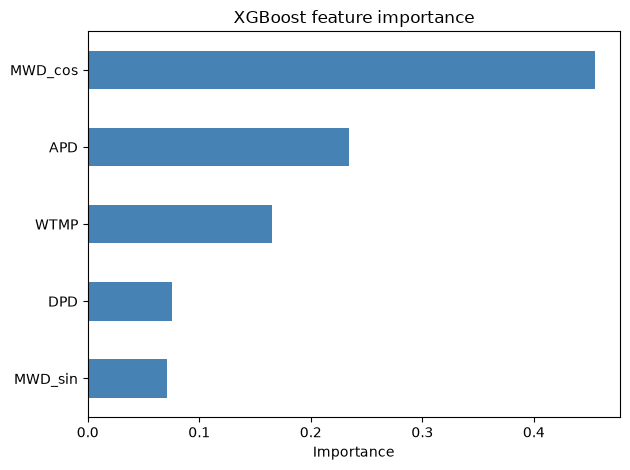

In [9]:
importance = pd.Series(
    xgb_model.feature_importances_,
    index=X.columns
).sort_values()

importance.plot(
    kind="barh",
    color="steelblue",
    title="XGBoost feature importance"
)

plt.xlabel("Importance")
plt.tight_layout()
plt.show()

In [10]:
n_trees_list = [2, 10, 25, 50, 100, 250, 500, 1000]

train_rmse = []
val_rmse = []

for n_trees in n_trees_list:

    model = XGBRegressor(
        n_estimators=n_trees,
        learning_rate=0.1,
        max_depth=3,
        objective="reg:squarederror",
        random_state=42,
        n_jobs=-1
    )

    model.fit(X_train, y_train)

In [11]:
records = []

for n_trees in n_trees_list:

    model = XGBRegressor(
        n_estimators=n_trees,
        learning_rate=0.1,
        max_depth=3,
        objective="reg:squarederror",
        random_state=42,
        n_jobs=-1
    )

    model.fit(X_train, y_train)

    train_predictions = model.predict(X_train)
    val_predictions = model.predict(X_val)

    records.append({
        "Boosting iterations": n_trees,
        "Training RMSE": np.sqrt(
            mean_squared_error(y_train, train_predictions)
        ),
        "Validation RMSE": np.sqrt(
            mean_squared_error(y_val, val_predictions)
        )
    })



In [12]:
iteration_results = pd.DataFrame(records)

print(iteration_results.round(4).to_string(index=False))


 Boosting iterations  Training RMSE  Validation RMSE
                   2         0.4908           0.4729
                  10         0.4093           0.3935
                  25         0.3633           0.3536
                  50         0.3415           0.3374
                 100         0.3284           0.3265
                 250         0.3080           0.3115
                 500         0.2925           0.3037
                1000         0.2732           0.2970


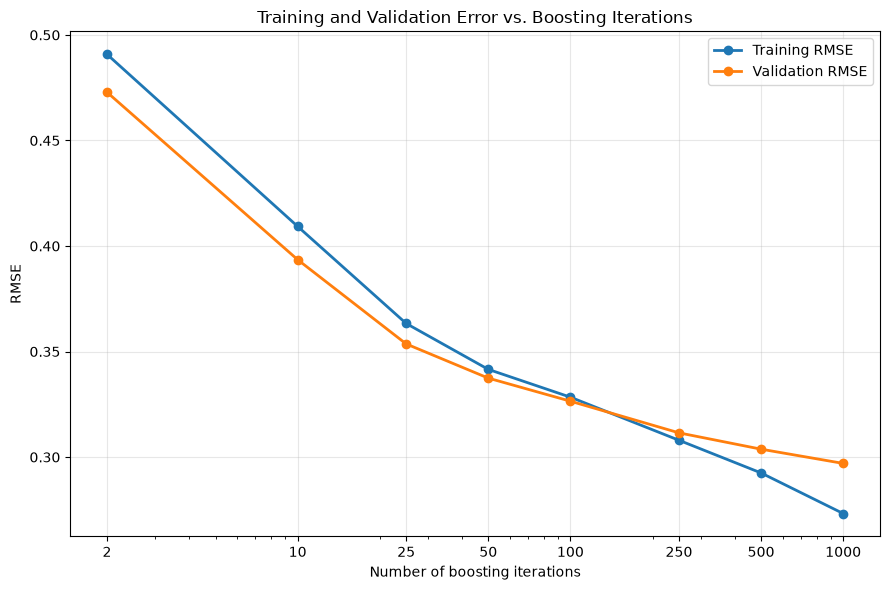

In [13]:
plt.figure(figsize=(9, 6))

plt.plot(
    iteration_results["Boosting iterations"],
    iteration_results["Training RMSE"],
    marker="o",
    linewidth=2,
    label="Training RMSE"
)

plt.plot(
    iteration_results["Boosting iterations"],
    iteration_results["Validation RMSE"],
    marker="o",
    linewidth=2,
    label="Validation RMSE"
)

plt.xscale("log")
plt.xticks(n_trees_list, n_trees_list)

plt.xlabel("Number of boosting iterations")
plt.ylabel("RMSE")
plt.title("Training and Validation Error vs. Boosting Iterations")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


In [14]:
best_row = iteration_results.loc[
    iteration_results["Validation RMSE"].idxmin()
]

print(
    "\nBest number of iterations:",
    int(best_row["Boosting iterations"])
)

print(
    "Lowest validation RMSE:",
    round(best_row["Validation RMSE"], 4)
)


Best number of iterations: 1000
Lowest validation RMSE: 0.297


In [15]:
best_row = iteration_results.loc[
    iteration_results["Validation RMSE"].idxmin()
]

row_1000 = iteration_results[
    iteration_results["Boosting iterations"] == 1000
].iloc[0]

print("Best validation result:")
print(best_row)

print("\nResult at 1,000 iterations:")
print(row_1000)

print(
    "\nValidation RMSE increase:",
    row_1000["Validation RMSE"] -
    best_row["Validation RMSE"]
)

Best validation result:
Boosting iterations    1000.000000
Training RMSE             0.273245
Validation RMSE           0.296998
Name: 7, dtype: float64

Result at 1,000 iterations:
Boosting iterations    1000.000000
Training RMSE             0.273245
Validation RMSE           0.296998
Name: 7, dtype: float64

Validation RMSE increase: 0.0


In [16]:
early_stop_model = XGBRegressor(
    n_estimators=5000,          # upper limit
    learning_rate=0.1,
    max_depth=3,
    objective="reg:squarederror",
    eval_metric="rmse",
    early_stopping_rounds=10,
    random_state=42,
    n_jobs=-1
)

early_stop_model.fit(
    X_train,
    y_train,
    eval_set=[(X_val, y_val)],
    verbose=False
)


,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,None
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",10
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",'rmse'
,feature_types feature_types: typing.Optional[typing.Sequence[str]].. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


In [17]:
optimal_iterations = early_stop_model.best_iteration + 1

print("Optimal number of boosting iterations:", optimal_iterations)
print("Best validation RMSE:", early_stop_model.best_score)

Optimal number of boosting iterations: 550
Best validation RMSE: 0.30277044693516025


In [18]:
def rmse(y_true, y_pred):
    return np.sqrt(mean_squared_error(y_true, y_pred))

In [19]:
best_xgb = XGBRegressor(
    n_estimators=5000,
    learning_rate=0.1,
    max_depth=3,
    objective="reg:squarederror",
    eval_metric="rmse",
    early_stopping_rounds=10,
    random_state=42,
    n_jobs=-1
)

best_xgb.fit(
    X_train,
    y_train,
    eval_set=[(X_val, y_val)],
    verbose=False
)

print(
    "\nOptimal XGBoost boosting iterations:",
    best_xgb.best_iteration + 1
)
print("XGBoost validation RMSE:", round(best_xgb.best_score, 4))


Optimal XGBoost boosting iterations: 550
XGBoost validation RMSE: 0.3028


In [20]:
tree_results = []
best_tree = None
best_tree_val_rmse = np.inf

for max_depth in [2, 3, 5, 7, 10, 15, 20, None]:
    for min_samples_leaf in [1, 5, 10, 20]:

        tree = DecisionTreeRegressor(
            max_depth=max_depth,
            min_samples_leaf=min_samples_leaf,
            random_state=42
        )

        tree.fit(X_train, y_train)

        validation_rmse = rmse(
            y_val,
            tree.predict(X_val)
        )

        tree_results.append({
            "max_depth": max_depth,
            "min_samples_leaf": min_samples_leaf,
            "Validation RMSE": validation_rmse
        })

        if validation_rmse < best_tree_val_rmse:
            best_tree_val_rmse = validation_rmse
            best_tree = tree

print("\nSelected decision tree settings:")
print("max_depth:", best_tree.max_depth)
print("min_samples_leaf:", best_tree.min_samples_leaf)
print("Validation RMSE:", round(best_tree_val_rmse, 4))


Selected decision tree settings:
max_depth: 10
min_samples_leaf: 5
Validation RMSE: 0.313


In [21]:
models = {
    "XGBoost": best_xgb,
    "Decision tree": best_tree
}

test_results = pd.DataFrame([
    {
        "Model": name,
        "Test RMSE (m)": rmse(y_test, model.predict(X_test))
    }
    for name, model in models.items()
])

print("\nTest performance:")
print(test_results.round(4).to_string(index=False))


Test performance:
        Model  Test RMSE (m)
      XGBoost         0.3114
Decision tree         0.3222


In [22]:
importance_tables = {}

for name, model in models.items():

    result = permutation_importance(
        estimator=model,
        X=X_test,
        y=y_test,
        scoring="neg_root_mean_squared_error",
        n_repeats=30,
        random_state=42,
        n_jobs=1
    )

    importance = pd.DataFrame({
        "Feature": X_test.columns,
        "Importance": result.importances_mean,
        "Std": result.importances_std
    }).sort_values(
        "Importance",
        ascending=False
    ).reset_index(drop=True)

    importance_tables[name] = importance

    print(f"\n{name}: permutation importance")
    print(importance.round(4).to_string(index=False))

    print(
        f"Highest-ranked predictor for {name}:",
        importance.loc[0, "Feature"]
    )


XGBoost: permutation importance
Feature  Importance    Std
    APD      0.1585 0.0068
    DPD      0.1309 0.0062
   WTMP      0.1186 0.0065
MWD_cos      0.0841 0.0049
MWD_sin      0.0197 0.0027
Highest-ranked predictor for XGBoost: APD

Decision tree: permutation importance
Feature  Importance    Std
    DPD      0.1992 0.0083
    APD      0.1962 0.0090
MWD_cos      0.1543 0.0099
   WTMP      0.1269 0.0072
MWD_sin      0.0443 0.0026
Highest-ranked predictor for Decision tree: DPD


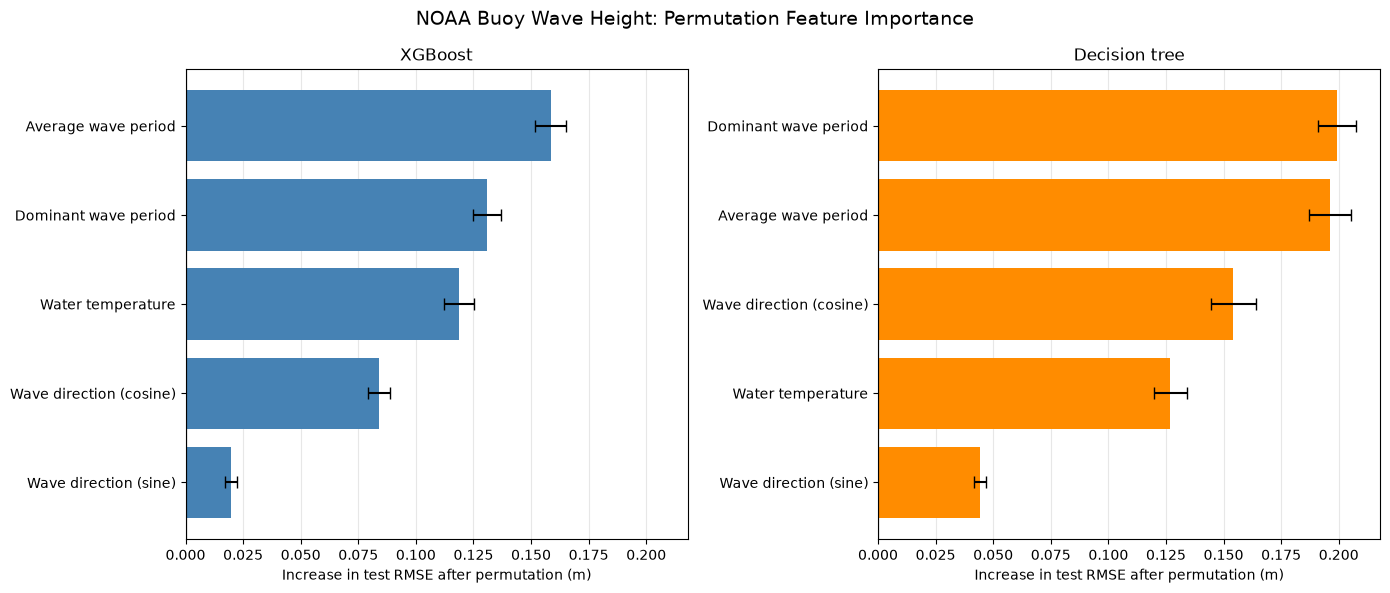

In [23]:
feature_labels = {
    "DPD": "Dominant wave period",
    "APD": "Average wave period",
    "MWD_sin": "Wave direction (sine)",
    "MWD_cos": "Wave direction (cosine)",
    "WTMP": "Water temperature"
}

fig, axes = plt.subplots(
    1, 2,
    figsize=(14, 6),
    sharex=True
)

for ax, (name, importance) in zip(
    axes, importance_tables.items()
):
    # Ascending order puts the largest bar at the top
    plot_data = importance.sort_values("Importance")

    ax.barh(
        plot_data["Feature"].map(feature_labels),
        plot_data["Importance"],
        xerr=plot_data["Std"],
        capsize=4,
        color="steelblue" if name == "XGBoost" else "darkorange"
    )

    ax.axvline(0, color="black", linewidth=0.8)
    ax.set_title(name)
    ax.set_xlabel("Increase in test RMSE after permutation (m)")
    ax.grid(axis="x", alpha=0.3)
    ax.set_axisbelow(True)

fig.suptitle(
    "NOAA Buoy Wave Height: Permutation Feature Importance",
    fontsize=14
)

plt.tight_layout()
plt.show()

In [24]:
models = {
    "XGBoost": best_xgb,
    "Decision tree": best_tree,
    "Linear regression": linear_model
}

feature_labels = {
    "DPD": "Dominant wave period",
    "APD": "Average wave period",
    "MWD_sin": "Wave direction (sine)",
    "MWD_cos": "Wave direction (cosine)",
    "WTMP": "Water temperature"
}

importance_tables = {}
performance = []

In [26]:
for name, model in models.items():

    predictions = model.predict(X_test)
    test_rmse = np.sqrt(mean_squared_error(y_test, predictions))

    performance.append({
        "Model": name,
        "Test RMSE (m)": test_rmse
    })

    result = permutation_importance(
        model,
        X_test,
        y_test,
        scoring="neg_root_mean_squared_error",
        n_repeats=30,
        random_state=42,
        n_jobs=1
    )

    importance = pd.DataFrame({
        "Feature": X_test.columns,
        "Mean RMSE increase (m)": result.importances_mean,
        "Std": result.importances_std
    }).sort_values(
        "Mean RMSE increase (m)",
        ascending=False
    ).reset_index(drop=True)

    importance_tables[name] = importance

    print(f"\n{name}: permutation feature importance")
    print(importance.round(4).to_string(index=False))

    top_feature = importance.loc[0, "Feature"]
    print("Highest-ranked variable:", feature_labels[top_feature])

print("\nModel performance:")
print(pd.DataFrame(performance).round(4).to_string(index=False))



XGBoost: permutation feature importance
Feature  Mean RMSE increase (m)    Std
    APD                  0.1585 0.0068
    DPD                  0.1309 0.0062
   WTMP                  0.1186 0.0065
MWD_cos                  0.0841 0.0049
MWD_sin                  0.0197 0.0027
Highest-ranked variable: Average wave period

Decision tree: permutation feature importance
Feature  Mean RMSE increase (m)    Std
    DPD                  0.1992 0.0083
    APD                  0.1962 0.0090
MWD_cos                  0.1543 0.0099
   WTMP                  0.1269 0.0072
MWD_sin                  0.0443 0.0026
Highest-ranked variable: Dominant wave period

Linear regression: permutation feature importance
Feature  Mean RMSE increase (m)    Std
MWD_cos                  0.1339 0.0037
    APD                  0.0850 0.0037
MWD_sin                  0.0474 0.0027
   WTMP                  0.0209 0.0017
    DPD                  0.0065 0.0008
Highest-ranked variable: Wave direction (cosine)

Model performance:

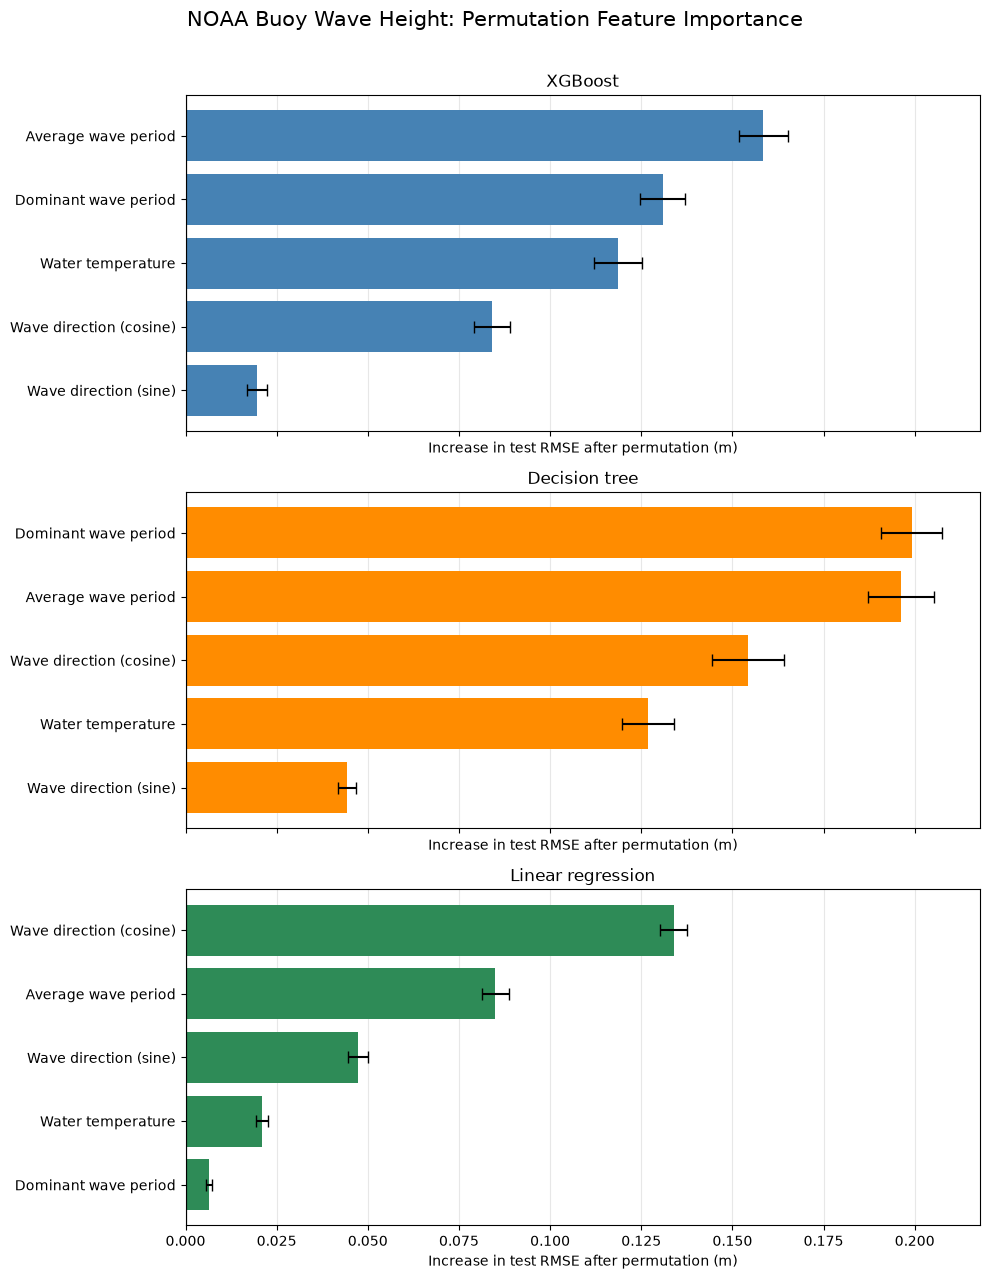

In [27]:
fig, axes = plt.subplots(
    3, 1,
    figsize=(10, 13),
    sharex=True
)

colors = ["steelblue", "darkorange", "seagreen"]

for ax, (name, importance), color in zip(
    axes,
    importance_tables.items(),
    colors
):
    plot_data = importance.sort_values("Mean RMSE increase (m)")

    ax.barh(
        plot_data["Feature"].map(feature_labels),
        plot_data["Mean RMSE increase (m)"],
        xerr=plot_data["Std"],
        color=color,
        capsize=4
    )

    ax.axvline(0, color="black", linewidth=0.8)
    ax.set_title(name)
    ax.set_xlabel("Increase in test RMSE after permutation (m)")
    ax.grid(axis="x", alpha=0.3)
    ax.set_axisbelow(True)

fig.suptitle(
    "NOAA Buoy Wave Height: Permutation Feature Importance",
    fontsize=15
)

plt.tight_layout(rect=[0, 0, 1, 0.97])
plt.show()

In [30]:
#These are different for different models


##1. How do they describe the permutation feature importance method we learned##
in class?
    They describe the permutation feature importance method as quick to compute and easily defined,
    highly understandable, but also discusses that they are sensitive to correlary features that
    may not have any effect on the data.

##2. Describe an additional method for explainability from this paper. How does it##
work? Is it model agnostic or model specific?
    LIME is a "method that fits a linear model on perturbations of the dataset around the example to be explained" (Flora et al, 2024).
    It works by creating sets of test data around one's data points, then all variations are weighted by how closely the test set was to the
    training set. LIME is agnostic.

3#3. Find potential scikitlearn functions for 5 of the methods described in the paper.##
Note: You don’t have to implement them.
    LIME
        explainer = lime.lime_tabular.LimeTabularExplainer(
        training_data=X_train.values,
        feature_names=X_train.columns,
        class_names=['Class 0', 'Class 1'],
        mode='classification'

    SHAP
        X, y = load_iris(return_X_y=True, as_frame=True)
        X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
        model = RandomForestClassifier()
        model.fit(X_train, y_train)
        explainer = shap.Explainer(model)
        shap_values = explainer(X_test)
            
    SAGE
        model = RandomForestClassifier()
        model.fit(X_train, y_train)
        imputer = sage.MarginalImputer(model, X_test[:100])
        estimator = sage.PermutationEstimator(imputer, loss='cross_entropy')
        sage_values = estimator(X_test, y_test)
        sage_values.plot(feature_names)
        
    Tree Interpreter
        model = DecisionTreeRegressor()
        model.fit(X_train, y_train)
        prediction, bias, contributions = ti.predict(model, X_test)
        print("Base value (Bias):", bias[0])
        print("Feature Contributions:", contributions[0])
        print("Final Prediction:", prediction[0])
    
    Permutation Importance
        model = RandomForestClassifier(random_state=42)
        model.fit(X_train, y_train)
        result = permutation_importance(
        model,
        X_test,
        y_test,
        n_repeats=10,
        random_state=42,
        n_jobs=-1)
        importance_df = pd.DataFrame(
        {"Feature": X_test.columns,
        "Importance_Mean": result.importances_mean,
        "Importance_Std": result.importances_std,}
        ).sort_values(by="Importance_Mean", ascending=False)
        print(importance_df.head(5))